<a href="https://colab.research.google.com/github/kko1225/Linear_Algebra/blob/main/ex02_transform_tiefighter_%EB%B0%B0%ED%8F%AC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 라이브러리 선언

In [86]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

INF = 1000  # 그림판 크기
LEN = 100   # 처음 사각형의 크기

### 축 그리기 및 사각형 그리기

In [87]:
def draw_axis(ax):
  ax.axhline(0, color='black', alpha=0.3)  # x-axis line
  ax.axvline(0, color='black', alpha=0.3)  # y-axis line
  ax.set_xlim(-INF, INF)
  ax.set_ylim(-INF, INF)
  ax.set_aspect('equal')  # 정사각형 모양으로 backboard 그리기

In [88]:
def draw_rectangle(ax, p1, p2, p3, p4):
  my_polygon = Polygon([p1, p2, p3, p4])
  ax.add_patch(my_polygon)

In [89]:
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  draw_rectangle(ax, p1, p2, p3, p4)

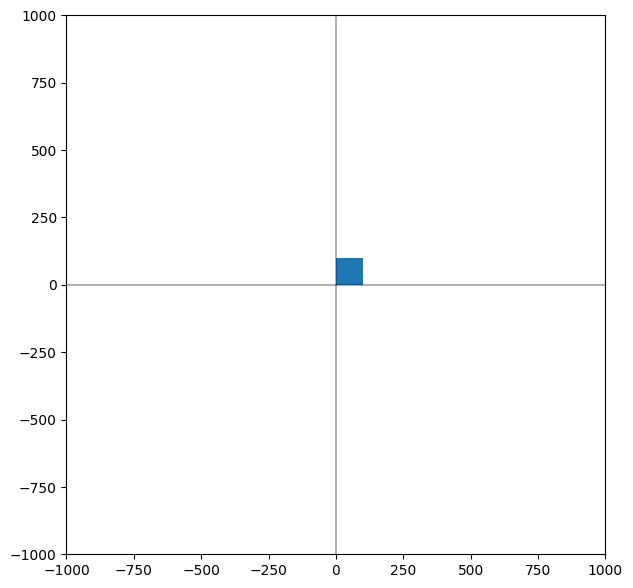

In [90]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()

### 본론
#### 1. 변환 구현
* translate(p, dx, dy)
* rotate(p, theta(라디언으로 받을지 세타로 받을지는 고르면 됨))  
* scale(p, sx, sy)  
* shear_x(p, sx)  
* shear_y(p, sy)  
* reflect_x(p)  
* reflect_y(p)   
* ...

In [91]:
# 점 p를 x축 방향으로 dx만큼, y축 방향으로 dy만큼 이동시킨 점 q를 구할 것
# q = T(dx, dy) p1
def translate(p, dx, dy):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 이동 변환 행렬 생성
  m = np.array([[1.0, 0.0, dx], [0.0, 1.0, dy], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [92]:
def rotate(p, theta): # 회전 변환
  hp = np.array([p[0], p[1], 1.0])

  m = np.array([[np.cos(theta), -np.sin(theta), 0], [np.sin(theta), np.cos(theta), 0.0], [0.0, 0.0, 1.0]])

  q = np.dot(m, hp)

  q = np.array([q[0], q[1]])
  return q

In [93]:
def scale(p, sx, sy): # 크기 변환
  hp = np.array([p[0], p[1], 1.0])

  m = np.array([[sx, 0.0, 0.0], [0.0, sy, 0.0], [0.0, 0.0, 1.0]])

  q = np.dot(m, hp)

  q = np.array([q[0], q[1]])
  return q

In [94]:
def shear_x(p, sx): # x축 방향 기울기 변환
  hp = np.array([p[0], p[1], 1.0])

  m = np.array([[1.0, sx, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]])

  q = np.dot(m, hp)

  q = np.array([q[0], q[1]])
  return q

In [95]:
def shear_y(p, sy): # y축 방향 기울기 변환
  hp = np.array([p[0], p[1], 1.0])

  m = np.array([[1.0, 0.0, 0.0], [sy, 1.0, 0.0], [0.0, 0.0, 1.0]])

  q = np.dot(m, hp)

  q = np.array([q[0], q[1]])
  return q

In [96]:
def reflect_x(p): # x축 대칭
  hp = np.array([p[0], p[1], 1.0])

  m = np.array([[1.0, 0.0, 0.0], [0.0, -1.0, 0.0], [0.0, 0.0, 1.0]])

  q = np.dot(m, hp)

  q = np.array([q[0], q[1]])
  return q

In [97]:
def reflect_y(p): # y축 대칭
  hp = np.array([p[0], p[1], 1.0])

  m = np.array([[-1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]])

  q = np.dot(m, hp)

  q = np.array([q[0], q[1]])
  return q

In [98]:
def reflect_origin(p): # 원점 대칭
  hp = np.array([p[0], p[1], 1.0])

  m = np.array([[-1.0, 0.0, 0.0], [0.0, -1.0, 0.0], [0.0, 0.0, 1.0]])

  q = np.dot(m, hp)

  q = np.array([q[0], q[1]])
  return q

In [99]:
def reflect_yx(p): # y=x 대칭
  hp = np.array([p[0], p[1], 1.0])

  m = np.array([[0.0, 1.0, 0.0], [1.0, 0.0, 0.0], [0.0, 0.0, 1.0]])

  q = np.dot(m, hp)

  q = np.array([q[0], q[1]])
  return q

#### 2. 파트 그리기
* draw_cockpit(p1, p2, p3, p4)    # 중앙 조종석
* draw_left_arm(p1, p2, p3, p4)   # 왼쪽 날개축
* draw_left_wing(p1, p2, p3, p4)  # 왼쪽 날개
* draw_right_arm(p1, p2, p3, p4)  # 오른쪽 날개축
* draw_right_wing(p1, p2, p3, p4) # 오른쪽 날개

In [109]:
def draw_cockpit(ax, p1, p2, p3, p4):  # 중앙 조종석
  # 1. 사각형을 원점으로 이동 변환
  # q = T(-LEN/2, -LEN/2)p
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)

  # 2. 크기 변환: S(5, 5)
  s = 5
  q1 = scale(q1, s, s)
  q2 = scale(q2, s, s)
  q3 = scale(q3, s, s)
  q4 = scale(q4, s, s)

  # 3. 회전 변환: R(pi/4)
  q1 = rotate(q1, np.pi/4.0)
  q2 = rotate(q2, np.pi/4.0)
  q3 = rotate(q3, np.pi/4.0)
  q4 = rotate(q4, np.pi/4.0)

  # 4. polygon 그리기
  draw_rectangle(ax, q1, q2, q3, q4)

In [101]:
def draw_left_arm(ax, p1, p2, p3, p4): # 왼쪽 날개축
  # 1. 사각형을 원점으로 이동 변환
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)

  # 2. 크기 변환: S(3, 2)
  sx, sy = 3, 2
  q1 = scale(q1, sx, sy)
  q2 = scale(q2, sx, sy)
  q3 = scale(q3, sx, sy)
  q4 = scale(q4, sx, sy)

  # 3. x축 방향 기울기 변환
  q1 = shear_x(q1, -4)
  q2 = shear_x(q2, -4)
  q3 = shear_x(q3, -4)
  q4 = shear_x(q4, -4)

  # 4. 왼쪽 날개축 위치로 이동 변환
  q1 = translate(q1, 400, 100)
  q2 = translate(q2, 400, 100)
  q3 = translate(q3, 400, 100)
  q4 = translate(q4, 400, 100)

  # 5. 위쪽 절반 그리기
  draw_rectangle(ax, q1, q2, q3, q4)

  # 6. x축 반전 및 아래쪽 절반 그리기
  q1 = reflect_x(q1)
  q2 = reflect_x(q2)
  q3 = reflect_x(q3)
  q4 = reflect_x(q4)
  draw_rectangle(ax, q1, q2, q3, q4)

In [102]:
def draw_left_wing(ax, p1, p2, p3, p4): # 왼쪽 날개
  # 1. 사각형을 원점으로 이동 변환
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)

  # 2. 크기 변환: S(1, 6)
  sx, sy = 1, 6
  q1 = scale(q1, sx, sy)
  q2 = scale(q2, sx, sy)
  q3 = scale(q3, sx, sy)
  q4 = scale(q4, sx, sy)

  # 3. y축 방향 기울기 변환
  q1 = shear_y(q1, 2)
  q2 = shear_y(q2, 2)
  q3 = shear_y(q3, 2)
  q4 = shear_y(q4, 2)

  # 4. 왼쪽 날개 위치로 이동 변환
  q1 = translate(q1, 900, 200)
  q2 = translate(q2, 900, 200)
  q3 = translate(q3, 900, 200)
  q4 = translate(q4, 900, 200)

  # 5. 위쪽 절반 그리기
  draw_rectangle(ax, q1, q2, q3, q4)

  # 6. x축 반전 및 아래쪽 절반 그리기
  q1 = reflect_x(q1)
  q2 = reflect_x(q2)
  q3 = reflect_x(q3)
  q4 = reflect_x(q4)
  draw_rectangle(ax, q1, q2, q3, q4)

In [103]:
def draw_right_arm(ax, p1, p2, p3, p4): # 오른쪽 날개축
  # 1. 사각형을 원점으로 이동 변환
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)

  # 2. 크기 변환: S(3, 2)
  sx, sy = 3, 2
  q1 = scale(q1, sx, sy)
  q2 = scale(q2, sx, sy)
  q3 = scale(q3, sx, sy)
  q4 = scale(q4, sx, sy)

  # 3. x축 방향 기울기 변환
  q1 = shear_x(q1, 4)
  q2 = shear_x(q2, 4)
  q3 = shear_x(q3, 4)
  q4 = shear_x(q4, 4)

  # 4. 오른쪽 날개축 위치로 이동 변환
  q1 = translate(q1, -400, 100)
  q2 = translate(q2, -400, 100)
  q3 = translate(q3, -400, 100)
  q4 = translate(q4, -400, 100)

  # 5. 위쪽 절반 그리기
  draw_rectangle(ax, q1, q2, q3, q4)

  # 6. x축 반전 및 아래쪽 절반 그리기
  q1 = reflect_x(q1)
  q2 = reflect_x(q2)
  q3 = reflect_x(q3)
  q4 = reflect_x(q4)
  draw_rectangle(ax, q1, q2, q3, q4)

In [104]:
def draw_right_wing(ax, p1, p2, p3, p4): # 오른쪽 날개
  # 1. 사각형을 원점으로 이동 변환
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)

  # 2. 크기 변환: S(1, 6)
  sx, sy = 1, 6
  q1 = scale(q1, sx, sy)
  q2 = scale(q2, sx, sy)
  q3 = scale(q3, sx, sy)
  q4 = scale(q4, sx, sy)

  # 3. y축 방향 기울기 변환
  q1 = shear_y(q1, 2)
  q2 = shear_y(q2, 2)
  q3 = shear_y(q3, 2)
  q4 = shear_y(q4, 2)

  # 4. 오른쪽 날개 위치로 이동 변환
  q1 = translate(q1, 900, 200)
  q2 = translate(q2, 900, 200)
  q3 = translate(q3, 900, 200)
  q4 = translate(q4, 900, 200)

  # 5. 위쪽 절반 그리기
  q1 = reflect_y(q1)
  q2 = reflect_y(q2)
  q3 = reflect_y(q3)
  q4 = reflect_y(q4)
  draw_rectangle(ax, q1, q2, q3, q4)

  # 6. x축 반전 및 아래쪽 절반 그리기
  q1 = reflect_x(q1)
  q2 = reflect_x(q2)
  q3 = reflect_x(q3)
  q4 = reflect_x(q4)
  draw_rectangle(ax, q1, q2, q3, q4)

In [110]:
# 2. tiefigher 그리기
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  draw_cockpit(ax, p1, p2, p3, p4) # 1. 중앙 조종석
  draw_left_arm(ax, p1, p2, p3, p4) # 2. 왼쪽 날개축
  draw_left_wing(ax, p1, p2, p3, p4) # 3. 왼쪽 날개
  draw_right_arm(ax, p1, p2, p3, p4) # 4. 오른쪽 날개축
  draw_right_wing(ax, p1, p2, p3, p4) # 5. 오른쪽 날개

### 3. main

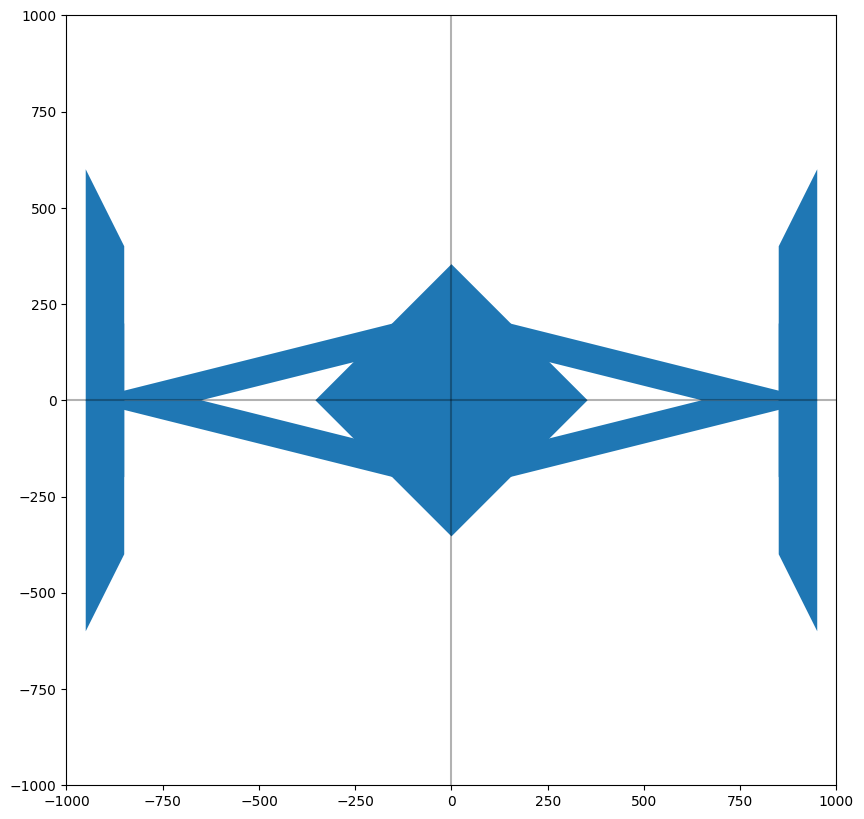

In [111]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(10,10))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()